# Notebook 08: Evaluation and Baseline Models

This notebook implements the evaluation framework used throughout the project and the
non-GNN baseline recommenders.

The evaluator is implemented and validated first because an error in evaluation may
produce plausible but incorrect metrics. It is therefore checked against a popularity
baseline before more complex models are trained.

Evaluation uses full-catalogue ranking: every sampled user is scored against all
items, with previously interacted items removed from the candidate set. Users are
sampled, but items are never sampled, following Krichene and Rendle (2020), who showed
that item sampling can produce inconsistent metrics and even reverse model rankings.

Everything in this notebook runs on the `small` dataset under both splitting
protocols.

## 1. Imports and Configuration

In [1]:
%load_ext autoreload
%autoreload 2

import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
import torch

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src import graph as gr

# Paths 
SUBSETS_DIR = PROJECT_ROOT / "data" / "processed" / "subsets_earliest"
FEATURES_DIR = PROJECT_ROOT / "data" / "processed" / "features_earliest"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = PROJECT_ROOT / "figures"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Experiment Config
SUBSET = "small"
PROTOCOLS = ["last_out", "timestamp"]

SAMPLING = "user"   # matches the LightGCN reference implementation, see Notebook 09

K_VALUES = [10, 20]
EVAL_BATCH_USERS = 1024        # users scored at once
MASK_VALIDATION_IN_TEST = True # user has already consumed the validation item

SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Model Config
ITEMKNN_NEIGHBOURS = 100
MF_DIM = 64
MF_EPOCHS = 200
MF_BATCH = 8192
MF_LR = 1e-3
MF_REG = 1e-4

torch.manual_seed(SEED)
np.random.seed(SEED)

print(f"device: {DEVICE}")
print(f"subset: {SUBSET}, protocols: {PROTOCOLS}")
print(f"K: {K_VALUES}, eval batch: {EVAL_BATCH_USERS} users")

device: cuda
subset: small, protocols: ['last_out', 'timestamp']
K: [10, 20], eval batch: 1024 users


## 2. Load the splits

Only interaction data are loaded. No item features or graph structure are required,
since all baselines use interactions alone. This establishes a reference point for
the GNN models introduced in Notebook 09.

Both protocols are loaded together so every baseline can be evaluated without
reloading the data.

In [2]:
def load_protocol(subset, protocol):
    base = SUBSETS_DIR / subset
    splits = base / "splits" / protocol

    parts = {
        name: pq.read_table(splits / f"{name}.parquet",
                            columns=["user_idx", "item_idx"]).to_pandas()
        for name in ["train", "validation", "test"]
    }
    return {
        "protocol": protocol,
        "n_users": len(pq.read_table(base / "user_mapping.parquet")),
        "n_items": len(pq.read_table(base / "item_mapping.parquet")),
        "eval_users": pq.read_table(
            splits / "eval_users.parquet").to_pandas()["user_idx"].to_numpy(),
        "cold_items": pq.read_table(
            splits / "cold_items.parquet").to_pandas()["item_idx"].to_numpy(),
        **parts,
    }


data = {p: load_protocol(SUBSET, p) for p in PROTOCOLS}

rows = []
for protocol, d in data.items():
    rows.append({
        "protocol": protocol,
        "users": d["n_users"],
        "items": d["n_items"],
        "train": len(d["train"]),
        "validation": len(d["validation"]),
        "test": len(d["test"]),
        "eval_users": len(d["eval_users"]),
        "test_items_per_eval_user": round(
            d["test"][d["test"].user_idx.isin(d["eval_users"])].shape[0]
            / len(d["eval_users"]), 3),
    })

pd.DataFrame(rows)

,protocol,users,items,train,validation,test,eval_users,test_items_per_eval_user
0,last_out,258597,105298,1829582,258597,258597,50000,1.000
1,timestamp,258597,105298,2020041,165504,161231,50000,2.099


In [3]:
for protocol, d in data.items():
    # evaluation users must have training history and appear in test
    train_users = set(d["train"].user_idx.unique())
    test_users = set(d["test"].user_idx.unique())
    assert set(d["eval_users"]).issubset(train_users)
    assert set(d["eval_users"]).issubset(test_users)
    print(f"{protocol}: {len(d['eval_users']):,} eval users, all with training "
          f"history and test interactions")

last_out: 50,000 eval users, all with training history and test interactions
timestamp: 50,000 eval users, all with training history and test interactions


### Sparsity

The mean number of training interactions per user hides how skewed the distribution is,
so the percentiles matter more than the average here. This is the figure the baseline
results keep coming back to: how much history a model actually has to work with for a
typical user.

In [4]:
from pathlib import Path

import pandas as pd
import pyarrow.parquet as pq

SPLITS_ROOT = Path("../data/processed/subsets_earliest/small/splits")

rows = []
for protocol in ["last_out", "timestamp"]:
    train = pq.read_table(
        SPLITS_ROOT / protocol / "train.parquet",
        columns=["user_idx", "item_idx"],
    ).to_pandas()

    counts = train.groupby("user_idx").size()
    rows.append({
        "protocol": protocol,
        "users_with_training": int(counts.size),   # excludes users with none
        "min": int(counts.min()),
        "p25": int(counts.quantile(0.25)),
        "median": int(counts.median()),
        "mean": round(float(counts.mean()), 2),
        "p75": int(counts.quantile(0.75)),
        "max": int(counts.max()),
        "share <= 5": round(float((counts <= 5).mean()), 3),
    })

pd.DataFrame(rows)

,protocol,users_with_training,min,p25,median,mean,p75,max,share <= 5
0,last_out,258597,3,3,5,7.08,8,629,0.587
1,timestamp,253769,1,5,6,7.96,9,631,0.412


## 3. Metric Verification

A synthetic example with three users and ten items verifies the evaluator against
known metric values. The test covers masking of previously seen items, different hit
positions, multiple relevant items, correct NDCG normalisation, and batched
evaluation.

In [5]:
from src import evaluation as ev

SCORES = torch.tensor([
    [20., 0., 10., 0., 0., 0., 0., 0., 0., 0.],   # item 0 masked -> item 2 ranks 1st
    [ 3., 2.,  0., 0., 0., 1., 0., 0., 0., 0.],   # item 5 ranks 3rd
    [10., 8.,  7., 0., 0., 0., 0., 9., 6., 0.],   # item 7 ranks 2nd, item 8 ranks 5th
], device=DEVICE)

toy = ev.Evaluator.from_frames(
    ground_truth=pd.DataFrame({"user_idx": [0, 1, 2, 2], "item_idx": [2, 5, 7, 8]}),
    mask_frames=[pd.DataFrame({"user_idx": [0], "item_idx": [0]})],
    eval_users=np.array([0, 1, 2]),
    n_users=3,
    n_items=10,
    k_values=[3],
    device=DEVICE,
    batch_users=2,
)

result = toy.evaluate(lambda users: SCORES[users])

expected = {
    "hit_rate@3": 1.0,
    "recall@3":   (1 + 1 + 0.5) / 3,
    "ndcg@3":     (1.0 + 0.5 + 0.630930 / 1.630930) / 3,
    "mrr@3":      (1 + 1/3 + 0.5) / 3,
}

for name, want in expected.items():
    got = result["means"][name]
    print(f"{name:>12}: got {got:.6f}, expected {want:.6f}")
    assert abs(got - want) < 1e-5, f"{name} is wrong"

print("\nmetrics verified against hand-computed values")

  hit_rate@3: got 1.000000, expected 1.000000
    recall@3: got 0.833333, expected 0.833333
      ndcg@3: got 0.628951, expected 0.628951
       mrr@3: got 0.611111, expected 0.611111

metrics verified against hand-computed values


In [ ]:
# masking must actually remove item 0 for user 0, without it the metrics would
# still look reasonable, which is what makes this failure mode dangerous
unmasked = ev.Evaluator.from_frames(
    ground_truth=pd.DataFrame({"user_idx": [0], "item_idx": [2]}),
    mask_frames=[pd.DataFrame({"user_idx": [], "item_idx": []}, dtype="int64")],
    eval_users=np.array([0]),
    n_users=1, n_items=10, k_values=[1], device=DEVICE,
)
masked = ev.Evaluator.from_frames(
    ground_truth=pd.DataFrame({"user_idx": [0], "item_idx": [2]}),
    mask_frames=[pd.DataFrame({"user_idx": [0], "item_idx": [0]})],
    eval_users=np.array([0]),
    n_users=1, n_items=10, k_values=[1], device=DEVICE,
)

print(f"unmasked hit_rate@1: {unmasked.evaluate(lambda u: SCORES[u])['means']['hit_rate@1']}")
print(f"masked   hit_rate@1: {masked.evaluate(lambda u: SCORES[u])['means']['hit_rate@1']}")
assert unmasked.evaluate(lambda u: SCORES[u])["means"]["hit_rate@1"] == 0.0
assert masked.evaluate(lambda u: SCORES[u])["means"]["hit_rate@1"] == 1.0
print("masking confirmed to change the ranking")

unmasked hit_rate@1: 0.0
masked   hit_rate@1: 1.0
masking confirmed to change the ranking


## 4. Evaluators for the Real Data

One evaluator is created for each splitting protocol. The ground truth is the test
partition, while the mask contains all previous user interactions.

Both training and validation interactions are masked because they would already have
been consumed by the time the test interaction occurs. This is a stricter evaluation
than masking training interactions only and is reported alongside the results.

In [7]:
evaluators = {}
for protocol, d in data.items():
    mask_frames = [d["train"]]
    if MASK_VALIDATION_IN_TEST:
        mask_frames.append(d["validation"])

    evaluators[protocol] = ev.Evaluator.from_frames(
        ground_truth=d["test"],
        mask_frames=mask_frames,
        eval_users=d["eval_users"],
        n_users=d["n_users"],
        n_items=d["n_items"],
        k_values=K_VALUES,
        device=DEVICE,
        batch_users=EVAL_BATCH_USERS,
    )

    masked_per_user = np.diff(evaluators[protocol].mask_indptr)[d["eval_users"]]
    truth_per_user = np.diff(evaluators[protocol].truth_indptr)[d["eval_users"]]
    print(f"{protocol}: {len(d['eval_users']):,} users, "
          f"{masked_per_user.mean():.1f} items masked per user, "
          f"{truth_per_user.mean():.2f} relevant per user")

last_out: 50,000 users, 8.1 items masked per user, 1.00 relevant per user
timestamp: 50,000 users, 8.9 items masked per user, 2.10 relevant per user


## 5. Popularity Baseline and Evaluator Validation

Section 3 verified the metric calculations on a synthetic example. Here the complete
evaluation pipeline is validated on the real data in three ways.

- **Random recommendation:** observed metrics are compared with their expected values
  under random ranking to verify masking and ground-truth alignment.
- **Independent implementation:** popularity metrics are reproduced with a separate
  NumPy implementation to confirm the evaluator's correctness.
- **Structural checks:** metrics should increase with K, and under leave-last-out
  Recall@K must equal HitRate@K because each user has exactly one relevant item.

In [8]:
from src import baselines as bl

d = data["last_out"]
n_items = d["n_items"]

random_check = ev.Evaluator.from_frames(
    ground_truth=d["test"],
    mask_frames=[d["train"], d["validation"]],
    eval_users=d["eval_users"],
    n_users=d["n_users"],
    n_items=n_items,
    k_values=[1000],
    device=DEVICE,
    batch_users=EVAL_BATCH_USERS,
)

observed = random_check.evaluate(
    bl.random_score_fn(n_items, DEVICE, seed=SEED), return_per_user=False
)["means"]["hit_rate@1000"]

mean_masked = np.diff(random_check.mask_indptr)[d["eval_users"]].mean()
expected = 1000 / (n_items - mean_masked)

print(f"random hit_rate@1000: observed {observed:.5f}, expected {expected:.5f}, "
      f"ratio {observed / expected:.3f}")
assert 0.85 < observed / expected < 1.15, "random baseline is off its expected value"

c:\Projects\gnn-recommender-dissertation\src\evaluation.py:144: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  user_tensor = torch.as_tensor(users, dtype=torch.long, device=self.device)


random hit_rate@1000: observed 0.00958, expected 0.00950, ratio 1.009


In [9]:
results = {}

for protocol, d in data.items():
    pop = bl.PopularityRecommender().fit(d["train"], d["n_items"])
    t0 = time.time()
    results[(protocol, "Popularity")] = evaluators[protocol].evaluate(
        pop.score_fn(DEVICE))
    print(f"{protocol}: evaluated in {time.time() - t0:.1f}s")

    if protocol == "last_out":
        popularity_last_out = pop

ev.metrics_to_frame({f"{p} / {m}": r for (p, m), r in results.items()}).round(5)

last_out: evaluated in 0.6s
timestamp: evaluated in 0.5s


,hit_rate@10,hit_rate@20,mrr@10,mrr@20,ndcg@10,ndcg@20,recall@10,recall@20
last_out / Popularity,0.0151,0.02228,0.00522,0.00573,0.00752,0.00935,0.0151,0.02228
timestamp / Popularity,0.0065,0.00846,0.00097,0.00111,0.00124,0.00156,0.0030,0.00414


In [ ]:
d = data["last_out"]
pop_order = np.argsort(-popularity_last_out.counts, kind="stable")

# indptr = index pointer
mask_indptr, mask_indices = evaluators["last_out"].mask_indptr, evaluators["last_out"].mask_indices
truth_indptr, truth_indices = evaluators["last_out"].truth_indptr, evaluators["last_out"].truth_indices

# taking the top K + max_masked candidates is enough: a user can never push more
# items out of the top K than they have masked
headroom = int(np.diff(mask_indptr)[d["eval_users"]].max())
candidates = pop_order[:max(K_VALUES) + headroom]

rng_check = np.random.default_rng(SEED)
sample = rng_check.choice(d["eval_users"], 2000, replace=False)

manual = {k: [] for k in K_VALUES}
for user in sample:
    masked = set(mask_indices[mask_indptr[user]:mask_indptr[user + 1]].tolist())
    truth = set(truth_indices[truth_indptr[user]:truth_indptr[user + 1]].tolist())
    ranked = [i for i in candidates if i not in masked]
    for k in K_VALUES:
        manual[k].append(int(len(truth & set(ranked[:k])) > 0))

positions = {u: i for i, u in enumerate(d["eval_users"])}
rows = np.array([positions[u] for u in sample])

for k in K_VALUES:
    from_evaluator = results[("last_out", "Popularity")]["per_user"][f"hit_rate@{k}"][rows]
    manual_k = np.array(manual[k], dtype=float)
    agree = (from_evaluator == manual_k).mean()
    print(f"hit_rate@{k}: evaluator {from_evaluator.mean():.5f}, "
          f"independent {manual_k.mean():.5f}, per-user agreement {agree:.4%}")
    assert agree == 1.0, f"implementations disagree at K={k}"

hit_rate@10: evaluator 0.01550, independent 0.01550, per-user agreement 100.0000%
hit_rate@20: evaluator 0.02100, independent 0.02100, per-user agreement 100.0000%


In [11]:
for (protocol, model), res in results.items():
    m = res["means"]
    assert all(0 <= v <= 1 for v in m.values()), "metric outside [0, 1]"
    assert m["hit_rate@20"] >= m["hit_rate@10"]
    assert m["ndcg@20"] >= m["ndcg@10"] - 1e-9
    if protocol == "last_out":
        # one relevant item per user makes these identical by definition
        for k in K_VALUES:
            assert abs(m[f"recall@{k}"] - m[f"hit_rate@{k}"]) < 1e-9

print("structural properties hold for all evaluated models")

structural properties hold for all evaluated models


## 6. ItemKNN

Item-item collaborative filtering scores each candidate item by summing its similarity
to the items in a user's training history.

Only the top 100 neighbours per item are retained, since storing the full similarity
matrix is impractical for this dataset.

Plain cosine similarity performed poorly because it overestimated similarities between
very infrequent items. A shrinkage term was therefore added to reduce unreliable
low-support similarities, with the optimal value selected using validation NDCG@10.

ItemKNN serves as a strong collaborative filtering baseline before comparing against
the GNN models.

In [ ]:
knn_results = {}

for protocol, d in data.items():
    print(f"{protocol}:")
    t0 = time.time()
    knn = bl.ItemKNNRecommender(n_neighbours=ITEMKNN_NEIGHBOURS).fit(
        d["train"], d["n_users"], d["n_items"])
    fit_seconds = time.time() - t0

    nnz_per_item = np.diff(knn.similarity.indptr)   # number of non-zeros
    print(f"  fitted in {fit_seconds/60:.1f} min, "
          f"{nnz_per_item.mean():.1f} neighbours per item on average, "
          f"{(nnz_per_item == 0).sum():,} items with none")

    t0 = time.time()
    results[(protocol, "ItemKNN")] = evaluators[protocol].evaluate(knn.score_fn(DEVICE))
    print(f"  evaluated in {time.time() - t0:.0f}s")

ev.metrics_to_frame({f"{p} / {m}": r for (p, m), r in results.items()}).round(5)

last_out:
  items 2,000/105,298
  items 22,000/105,298
  items 42,000/105,298
  items 62,000/105,298
  items 82,000/105,298
  items 102,000/105,298
  fitted in 0.0 min, 76.8 neighbours per item on average, 426 items with none
  evaluated in 9s
timestamp:
  items 2,000/105,298
  items 22,000/105,298
  items 42,000/105,298
  items 62,000/105,298
  items 82,000/105,298
  items 102,000/105,298
  fitted in 0.0 min, 73.6 neighbours per item on average, 8,628 items with none
  evaluated in 9s


,hit_rate@10,hit_rate@20,mrr@10,mrr@20,ndcg@10,ndcg@20,recall@10,recall@20
last_out / Popularity,0.01510,0.02228,0.00522,0.00573,0.00752,0.00935,0.01510,0.02228
timestamp / Popularity,0.00650,0.00846,0.00097,0.00111,0.00124,0.00156,0.00300,0.00414
last_out / ItemKNN,0.00418,0.00594,0.00185,0.00197,0.00239,0.00284,0.00418,0.00594
timestamp / ItemKNN,0.00206,0.00296,0.00078,0.00084,0.00064,0.00077,0.00104,0.00152


In [13]:
pop_counts = bl.PopularityRecommender().fit(
    data["last_out"]["train"], data["last_out"]["n_items"]).counts

sample_users = torch.as_tensor(data["last_out"]["eval_users"][:2048],
                               dtype=torch.long, device=DEVICE)

for name, fn in [("Popularity", popularity_last_out.score_fn(DEVICE)),
                 ("ItemKNN", knn.score_fn(DEVICE))]:
    top = torch.topk(fn(sample_users), 10, dim=1).indices.cpu().numpy()
    recommended_pop = pop_counts[top]
    print(f"{name:>11}: median training count of recommended items = "
          f"{np.median(recommended_pop):.0f}, mean = {recommended_pop.mean():.0f}")

 Popularity: median training count of recommended items = 3136, mean = 3699
    ItemKNN: median training count of recommended items = 5, mean = 68


Popularity recommends items appearing 3,136 times in training; ItemKNN with plain cosine
recommends items appearing 5 times, the minimum possible after 5-core filtering. Cosine
divides by how often each item occurs, so two obscure items bought by the same two users
score a perfect similarity while two popular items bought together hundreds of times
score lower.

In [14]:
d = data["last_out"]
sweep = []
for h in [0.0, 10.0, 50.0, 200.0, 1000.0]:
    knn_h = bl.ItemKNNRecommender(n_neighbours=ITEMKNN_NEIGHBOURS, shrinkage=h).fit(
        d["train"], d["n_users"], d["n_items"], verbose=False)
    m = evaluators["last_out"].evaluate(knn_h.score_fn(DEVICE),
                                        return_per_user=False)["means"]
    med_pop = np.median(pop_counts[
        torch.topk(knn_h.score_fn(DEVICE)(sample_users), 10, dim=1).indices.cpu().numpy()
    ])
    sweep.append({"shrinkage": h, "hit_rate@10": m["hit_rate@10"],
                  "ndcg@10": m["ndcg@10"], "median_rec_popularity": med_pop})
    print(sweep[-1])

pd.DataFrame(sweep)

{'shrinkage': 0.0, 'hit_rate@10': 0.00418000016361475, 'ndcg@10': 0.002388079883530736, 'median_rec_popularity': np.float32(5.0)}
{'shrinkage': 10.0, 'hit_rate@10': 0.009100000374019146, 'ndcg@10': 0.005363286938518286, 'median_rec_popularity': np.float32(7.0)}
{'shrinkage': 50.0, 'hit_rate@10': 0.014840000309050083, 'ndcg@10': 0.008231410756707191, 'median_rec_popularity': np.float32(34.0)}
{'shrinkage': 200.0, 'hit_rate@10': 0.01735999993979931, 'ndcg@10': 0.009479228407144547, 'median_rec_popularity': np.float32(280.0)}
{'shrinkage': 1000.0, 'hit_rate@10': 0.018780000507831573, 'ndcg@10': 0.009959741495549679, 'median_rec_popularity': np.float32(1049.0)}


,shrinkage,hit_rate@10,ndcg@10,median_rec_popularity
0,0.0,0.00418,0.002388,5.0
1,10.0,0.00910,0.005363,7.0
2,50.0,0.01484,0.008231,34.0
3,200.0,0.01736,0.009479,280.0
4,1000.0,0.01878,0.009960,1049.0


This sweep is scored against the test set and is a diagnostic, not a selection: it shows
the mechanism, with the median popularity of recommended items rising from 5 to 1,049 as
shrinkage increases. The value actually used is chosen on validation in the cells below.

In [15]:
validation_evaluators = {}
for protocol, d in data.items():
    validation_evaluators[protocol] = ev.Evaluator.from_frames(
        ground_truth=d["validation"],
        mask_frames=[d["train"]],
        eval_users=d["eval_users"],
        n_users=d["n_users"],
        n_items=d["n_items"],
        k_values=K_VALUES,
        device=DEVICE,
        batch_users=EVAL_BATCH_USERS,
    )
    n_truth = np.diff(validation_evaluators[protocol].truth_indptr)[d["eval_users"]]
    print(f"{protocol}: {(n_truth > 0).sum():,} of {len(d['eval_users']):,} "
          f"eval users have a validation item")

last_out: 50,000 of 50,000 eval users have a validation item
timestamp: 24,514 of 50,000 eval users have a validation item


In [16]:
d = data["last_out"]
sweep = []
for h in [0.0, 50.0, 200.0, 500.0, 1000.0, 2000.0, 5000.0, 10000.0]:
    knn_h = bl.ItemKNNRecommender(n_neighbours=ITEMKNN_NEIGHBOURS, shrinkage=h).fit(
        d["train"], d["n_users"], d["n_items"], verbose=False)
    m = validation_evaluators["last_out"].evaluate(
        knn_h.score_fn(DEVICE), return_per_user=False)["means"]
    sweep.append({"shrinkage": h, "val_hit_rate@10": m["hit_rate@10"],
                  "val_ndcg@10": m["ndcg@10"]})
    print(sweep[-1])

sweep = pd.DataFrame(sweep)
best_shrinkage = float(sweep.loc[sweep["val_ndcg@10"].idxmax(), "shrinkage"])
print(f"\nbest shrinkage on validation: {best_shrinkage}")
sweep

{'shrinkage': 0.0, 'val_hit_rate@10': 0.009479999542236328, 'val_ndcg@10': 0.005583412945270538}
{'shrinkage': 50.0, 'val_hit_rate@10': 0.029500000178813934, 'val_ndcg@10': 0.017324691638350487}
{'shrinkage': 200.0, 'val_hit_rate@10': 0.032919999212026596, 'val_ndcg@10': 0.018941357731819153}
{'shrinkage': 500.0, 'val_hit_rate@10': 0.033080000430345535, 'val_ndcg@10': 0.018801255151629448}
{'shrinkage': 1000.0, 'val_hit_rate@10': 0.03288000077009201, 'val_ndcg@10': 0.018570709973573685}
{'shrinkage': 2000.0, 'val_hit_rate@10': 0.032499998807907104, 'val_ndcg@10': 0.01816602610051632}
{'shrinkage': 5000.0, 'val_hit_rate@10': 0.032260000705718994, 'val_ndcg@10': 0.017908619716763496}
{'shrinkage': 10000.0, 'val_hit_rate@10': 0.032280001789331436, 'val_ndcg@10': 0.01790560968220234}

best shrinkage on validation: 200.0


,shrinkage,val_hit_rate@10,val_ndcg@10
0,0.0,0.00948,0.005583
1,50.0,0.02950,0.017325
2,200.0,0.03292,0.018941
3,500.0,0.03308,0.018801
4,1000.0,0.03288,0.018571
5,2000.0,0.03250,0.018166
6,5000.0,0.03226,0.017909
7,10000.0,0.03228,0.017906


In [17]:
# timestamp validation is a date window, so restrict tuning to users who have one
d_ts = data["timestamp"]
ts_val_users = d_ts["eval_users"][
    np.diff(validation_evaluators["timestamp"].truth_indptr)[d_ts["eval_users"]] > 0
]
ts_tuner = ev.Evaluator.from_frames(
    ground_truth=d_ts["validation"],
    mask_frames=[d_ts["train"]],
    eval_users=ts_val_users,
    n_users=d_ts["n_users"], n_items=d_ts["n_items"],
    k_values=K_VALUES, device=DEVICE, batch_users=EVAL_BATCH_USERS,
)

ts_sweep = []
for h in [0.0, 50.0, 200.0, 500.0, 1000.0, 2000.0]:
    knn_h = bl.ItemKNNRecommender(ITEMKNN_NEIGHBOURS, shrinkage=h).fit(
        d_ts["train"], d_ts["n_users"], d_ts["n_items"], verbose=False)
    m = ts_tuner.evaluate(knn_h.score_fn(DEVICE), return_per_user=False)["means"]
    ts_sweep.append({"shrinkage": h, "val_ndcg@10": m["ndcg@10"]})
    print(ts_sweep[-1])

ts_sweep = pd.DataFrame(ts_sweep)
best_shrinkage_ts = float(ts_sweep.loc[ts_sweep["val_ndcg@10"].idxmax(), "shrinkage"])
print(f"\nbest shrinkage (timestamp): {best_shrinkage_ts}")

{'shrinkage': 0.0, 'val_ndcg@10': 0.0015490688383579254}
{'shrinkage': 50.0, 'val_ndcg@10': 0.004835114814341068}
{'shrinkage': 200.0, 'val_ndcg@10': 0.005241678562015295}
{'shrinkage': 500.0, 'val_ndcg@10': 0.005326883401721716}
{'shrinkage': 1000.0, 'val_ndcg@10': 0.00522998534142971}
{'shrinkage': 2000.0, 'val_ndcg@10': 0.0050723315216600895}

best shrinkage (timestamp): 500.0


In [18]:
# selection is by validation NDCG@10; test is touched once, with the chosen value
chosen = {"last_out": best_shrinkage, "timestamp": best_shrinkage_ts}

for protocol, d in data.items():
    knn = bl.ItemKNNRecommender(ITEMKNN_NEIGHBOURS, shrinkage=chosen[protocol]).fit(
        d["train"], d["n_users"], d["n_items"], verbose=False)
    results[(protocol, "ItemKNN")] = evaluators[protocol].evaluate(knn.score_fn(DEVICE))
    print(f"{protocol}: shrinkage {chosen[protocol]}")

ev.metrics_to_frame({f"{p} / {m}": r for (p, m), r in results.items()}).round(5)

last_out: shrinkage 200.0
timestamp: shrinkage 500.0


,hit_rate@10,hit_rate@20,mrr@10,mrr@20,ndcg@10,ndcg@20,recall@10,recall@20
last_out / Popularity,0.01510,0.02228,0.00522,0.00573,0.00752,0.00935,0.01510,0.02228
timestamp / Popularity,0.00650,0.00846,0.00097,0.00111,0.00124,0.00156,0.00300,0.00414
last_out / ItemKNN,0.01736,0.02646,0.00709,0.00771,0.00948,0.01176,0.01736,0.02646
timestamp / ItemKNN,0.00730,0.01220,0.00259,0.00292,0.00217,0.00294,0.00374,0.00640


Selected: shrinkage 200 under leave-last-out and 500 under timestamp, both on validation
NDCG@10. With shrinkage, ItemKNN overtakes Popularity on both protocols.

## 7. BPR-MF

Matrix factorisation trained with Bayesian Personalised Ranking (Rendle et al., 2009).
Users and items are represented by learned embeddings, with recommendations generated
from their dot product. BPR directly optimises the ranking of observed items above
unobserved ones, matching the top-K recommendation task.

BPR-MF also serves as the 0-layer version of LightGCN. Using the same loss, sampler,
embedding dimension and optimiser allows any improvement from LightGCN to be
attributed to graph propagation rather than differences in training.

Training uses uniform negative sampling, explicit L2 regularisation on the embeddings,
and early stopping based on validation NDCG@10.

The training loop and model implementation are placed in `src/` so they can be reused
by the graph models in Notebook 09.

In [19]:
from src import models as md
from src import training as tr

d = data["last_out"]
probe = md.MatrixFactorization(d["n_users"], d["n_items"], MF_DIM, SEED)
probe_result = tr.train_bpr(
    probe, d["train"], d["n_items"], evaluator=None,
    epochs=3, batch_size=MF_BATCH, learning_rate=MF_LR, l2_reg=MF_REG, sampling=SAMPLING,
    device=DEVICE, seed=SEED, verbose=False,
)
per_epoch = probe_result["history"]["seconds"].mean()
print(f"{per_epoch:.1f}s per epoch -> {per_epoch * MF_EPOCHS / 60:.0f} min "
      f"for {MF_EPOCHS} epochs")

c:\Projects\gnn-recommender-dissertation\src\training.py:128: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:837.)
  epoch_loss += float(loss) * len(batch)


1.3s per epoch -> 4 min for 200 epochs


In [3]:
n_params = (data["last_out"]["n_users"] + data["last_out"]["n_items"]) * MF_DIM
print(f"parameters at dim {MF_DIM}: {n_params:,}")
print(f"training interactions:     {len(data['last_out']['train']):,}")
print(f"parameters per observation: {n_params / len(data['last_out']['train']):.1f}")

parameters at dim 64: 23,289,280
training interactions:     1,829,582
parameters per observation: 12.7


In [20]:
# early stopping uses the restricted evaluator for timestamp, since half its eval
# users have no validation item and would only add noise to the selection signal
tuning_evaluators = {"last_out": validation_evaluators["last_out"],
                     "timestamp": ts_tuner}

mf_models, mf_histories = {}, {}

for protocol, d in data.items():
    print(f"{protocol}:")
    model = md.MatrixFactorization(d["n_users"], d["n_items"], MF_DIM, SEED)

    t0 = time.time()
    outcome = tr.train_bpr(
        model, d["train"], d["n_items"],
        evaluator=tuning_evaluators[protocol],
        epochs=MF_EPOCHS, batch_size=MF_BATCH,
        learning_rate=MF_LR, l2_reg=MF_REG, sampling=SAMPLING,
        patience=5, eval_every=10, selection_metric="ndcg@10",
        device=DEVICE, seed=SEED,
    )
    print(f"  best epoch {outcome['best_epoch']}, "
          f"val ndcg@10 {outcome['best_val_score']:.5f}, "
          f"{(time.time() - t0) / 60:.1f} min\n")

    mf_models[protocol] = outcome["model"]
    mf_histories[protocol] = outcome["history"]
    results[(protocol, "BPR-MF")] = evaluators[protocol].evaluate(
        outcome["model"].score_fn())

last_out:
  epoch  10  loss 0.2834  val ndcg@10 0.00342  *
  epoch  20  loss 0.0940  val ndcg@10 0.00304
  epoch  30  loss 0.0429  val ndcg@10 0.00277
  epoch  40  loss 0.0240  val ndcg@10 0.00243
  epoch  50  loss 0.0153  val ndcg@10 0.00231
  epoch  60  loss 0.0108  val ndcg@10 0.00214
  stopping: no improvement for 5 evaluations
  best epoch 10, val ndcg@10 0.00342, 1.3 min

timestamp:
  epoch  10  loss 0.2862  val ndcg@10 0.00271  *
  epoch  20  loss 0.0896  val ndcg@10 0.00206
  epoch  30  loss 0.0395  val ndcg@10 0.00162
  epoch  40  loss 0.0221  val ndcg@10 0.00145
  epoch  50  loss 0.0143  val ndcg@10 0.00128
  epoch  60  loss 0.0104  val ndcg@10 0.00109
  stopping: no improvement for 5 evaluations
  best epoch 10, val ndcg@10 0.00271, 1.4 min



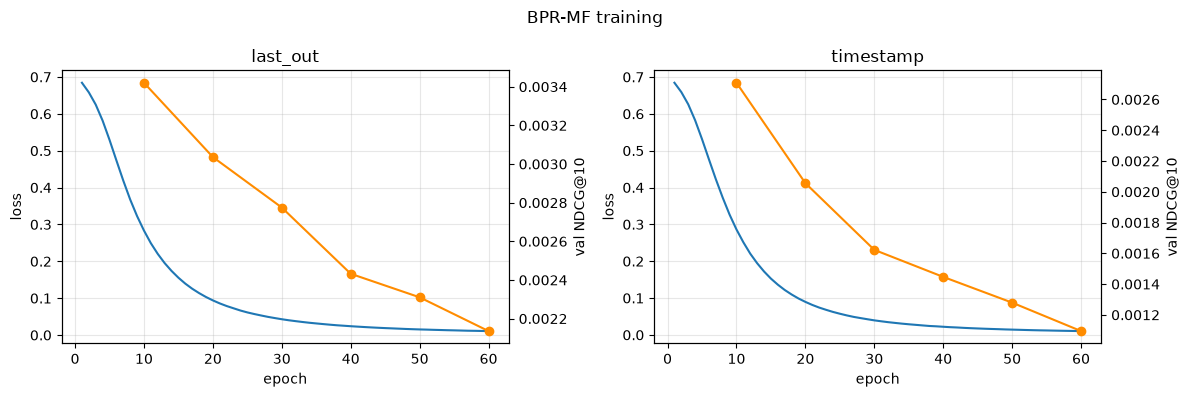

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (protocol, history) in zip(axes, mf_histories.items()):
    ax.plot(history["epoch"], history["loss"], label="BPR loss")
    ax.set_xlabel("epoch")
    ax.set_ylabel("loss")
    ax.grid(alpha=0.3)

    evaluated = history.dropna(subset=["val_ndcg@10"])
    twin = ax.twinx()
    twin.plot(evaluated["epoch"], evaluated["val_ndcg@10"], "o-",
              color="darkorange", label="val NDCG@10")
    twin.set_ylabel("val NDCG@10")
    ax.set_title(protocol)

fig.suptitle("BPR-MF training")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "08_bprmf_training.png", dpi=150, bbox_inches="tight")
plt.show()

In [22]:
ev.metrics_to_frame({f"{p} / {m}": r for (p, m), r in results.items()}).round(5)

,hit_rate@10,hit_rate@20,mrr@10,mrr@20,ndcg@10,ndcg@20,recall@10,recall@20
last_out / Popularity,0.01510,0.02228,0.00522,0.00573,0.00752,0.00935,0.01510,0.02228
timestamp / Popularity,0.00650,0.00846,0.00097,0.00111,0.00124,0.00156,0.00300,0.00414
last_out / ItemKNN,0.01736,0.02646,0.00709,0.00771,0.00948,0.01176,0.01736,0.02646
timestamp / ItemKNN,0.00730,0.01220,0.00259,0.00292,0.00217,0.00294,0.00374,0.00640
last_out / BPR-MF,0.00454,0.00704,0.00156,0.00173,0.00225,0.00288,0.00454,0.00704
timestamp / BPR-MF,0.00344,0.00584,0.00112,0.00128,0.00097,0.00134,0.00175,0.00307


The settings taken from the graph papers overfit on this data. Validation NDCG@10 peaks
at the first evaluation and falls from there while training loss drops by 96%, so the
model is memorising the training set rather than converging slowly. At dimension 64 it
holds 23.3 million parameters against 1.83 million training interactions, 12.7 per
observation. Dimension 64 is fixed in both LightGCN and NGCF, and 1e-4 is the
regularisation He et al. (2020) report as optimal in most of their settings. Their three
benchmarks average between 34 and 57 interactions per user, against 7.08 here, so the
same capacity and the same shrinkage are being applied to far thinner data.

In [23]:
d = data["last_out"]
mf_sweep = []

for reg in [1e-4, 1e-3, 1e-2, 1e-1]:
    model = md.MatrixFactorization(d["n_users"], d["n_items"], MF_DIM, SEED)
    outcome = tr.train_bpr(
        model, d["train"], d["n_items"],
        evaluator=tuning_evaluators["last_out"],
        epochs=40, batch_size=MF_BATCH, learning_rate=MF_LR, l2_reg=reg, sampling=SAMPLING,
        patience=10, eval_every=1, selection_metric="ndcg@10",
        device=DEVICE, seed=SEED, verbose=False,
    )
    mf_sweep.append({"l2_reg": reg, "best_epoch": outcome["best_epoch"],
                     "val_ndcg@10": outcome["best_val_score"]})
    print(mf_sweep[-1], flush=True)

pd.DataFrame(mf_sweep)

{'l2_reg': 0.0001, 'best_epoch': 7, 'val_ndcg@10': 0.0034956359304487705}
{'l2_reg': 0.001, 'best_epoch': 6, 'val_ndcg@10': 0.0033890765625983477}
{'l2_reg': 0.01, 'best_epoch': 7, 'val_ndcg@10': 0.002607319038361311}
{'l2_reg': 0.1, 'best_epoch': 14, 'val_ndcg@10': 0.008986914530396461}


,l2_reg,best_epoch,val_ndcg@10
0,0.0001,7,0.003496
1,0.0010,6,0.003389
2,0.0100,7,0.002607
3,0.1000,14,0.008987


Regularisation 0.1 gives nearly three times the performance of the paper's 1e-4. The cells
below narrow the range; they use varying epoch budgets and evaluators, so they show where
the optimum lies rather than providing directly comparable values.

In [24]:
pop_val = tuning_evaluators["last_out"].evaluate(
    popularity_last_out.score_fn(DEVICE), return_per_user=False)["means"]["ndcg@10"]
print(f"Popularity validation ndcg@10: {pop_val:.5f}")

Popularity validation ndcg@10: 0.00974


In [25]:
# smaller evaluator for hyperparameter search only; reported numbers still use 50,000
tune_small = ev.Evaluator.from_frames(
    ground_truth=data["last_out"]["validation"],
    mask_frames=[data["last_out"]["train"]],
    eval_users=data["last_out"]["eval_users"][:10_000],
    n_users=data["last_out"]["n_users"],
    n_items=data["last_out"]["n_items"],
    k_values=K_VALUES, device=DEVICE, batch_users=EVAL_BATCH_USERS,
)

pop_small = tune_small.evaluate(
    popularity_last_out.score_fn(DEVICE), return_per_user=False)["means"]["ndcg@10"]
print(f"Popularity on the tuning subset: {pop_small:.5f}\n")

Popularity on the tuning subset: 0.00998



In [26]:
d = data["last_out"]
grid = []

for dim in [16, 32, 64]:
    for reg in [0.1, 0.3, 1.0]:
        model = md.MatrixFactorization(d["n_users"], d["n_items"], dim, SEED)
        outcome = tr.train_bpr(
            model, d["train"], d["n_items"], evaluator=tune_small,
            epochs=50, batch_size=MF_BATCH, learning_rate=MF_LR, l2_reg=reg, sampling=SAMPLING,
            patience=8, eval_every=1, selection_metric="ndcg@10",
            device=DEVICE, seed=SEED, verbose=False,
        )
        grid.append({"dim": dim, "l2_reg": reg,
                     "best_epoch": outcome["best_epoch"],
                     "val_ndcg@10": outcome["best_val_score"],
                     "beats_popularity": outcome["best_val_score"] > pop_small})
        print(grid[-1], flush=True)

grid = pd.DataFrame(grid)
grid.pivot(index="dim", columns="l2_reg", values="val_ndcg@10").round(5)

{'dim': 16, 'l2_reg': 0.1, 'best_epoch': 18, 'val_ndcg@10': 0.009702403098344803, 'beats_popularity': False}
{'dim': 16, 'l2_reg': 0.3, 'best_epoch': 1, 'val_ndcg@10': 0.00016878829046618193, 'beats_popularity': False}
{'dim': 16, 'l2_reg': 1.0, 'best_epoch': 1, 'val_ndcg@10': 0.00019319597049616277, 'beats_popularity': False}
{'dim': 32, 'l2_reg': 0.1, 'best_epoch': 18, 'val_ndcg@10': 0.009534098207950592, 'beats_popularity': False}
{'dim': 32, 'l2_reg': 0.3, 'best_epoch': 1, 'val_ndcg@10': 4.999999873689376e-05, 'beats_popularity': False}
{'dim': 32, 'l2_reg': 1.0, 'best_epoch': 1, 'val_ndcg@10': 3.333333370392211e-05, 'beats_popularity': False}
{'dim': 64, 'l2_reg': 0.1, 'best_epoch': 18, 'val_ndcg@10': 0.009509189985692501, 'beats_popularity': False}
{'dim': 64, 'l2_reg': 0.3, 'best_epoch': 1, 'val_ndcg@10': 4.3067659134976566e-05, 'beats_popularity': False}
{'dim': 64, 'l2_reg': 1.0, 'best_epoch': 5, 'val_ndcg@10': 6.87882857164368e-05, 'beats_popularity': False}


l2_reg,0.1,0.3,1.0
dim,,,
16,0.00970,0.00017,0.00019
32,0.00953,0.00005,0.00003
64,0.00951,0.00004,0.00007


In [27]:
d = data["last_out"]
fine = []
for reg in [0.08, 0.12, 0.15, 0.20, 0.25]:
    model = md.MatrixFactorization(d["n_users"], d["n_items"], 32, SEED)
    outcome = tr.train_bpr(
        model, d["train"], d["n_items"], evaluator=tune_small,
        epochs=80, batch_size=MF_BATCH, learning_rate=MF_LR, l2_reg=reg, sampling=SAMPLING,
        patience=10, eval_every=1, selection_metric="ndcg@10",
        device=DEVICE, seed=SEED, verbose=False,
    )
    fine.append({"l2_reg": reg, "best_epoch": outcome["best_epoch"],
                 "val_ndcg@10": outcome["best_val_score"]})
    print(fine[-1], flush=True)

pd.DataFrame(fine)

{'l2_reg': 0.08, 'best_epoch': 23, 'val_ndcg@10': 0.008844645693898201}
{'l2_reg': 0.12, 'best_epoch': 18, 'val_ndcg@10': 0.008587433025240898}
{'l2_reg': 0.15, 'best_epoch': 19, 'val_ndcg@10': 0.006707123015075922}
{'l2_reg': 0.2, 'best_epoch': 1, 'val_ndcg@10': 9.999999747378752e-05}
{'l2_reg': 0.25, 'best_epoch': 1, 'val_ndcg@10': 9.999999747378752e-05}


,l2_reg,best_epoch,val_ndcg@10
0,0.08,23,0.008845
1,0.12,18,0.008587
2,0.15,19,0.006707
3,0.20,1,0.000100
4,0.25,1,0.000100


In [28]:
d = data["last_out"]
fine2 = []
for reg in [0.02, 0.03, 0.05, 0.065]:
    model = md.MatrixFactorization(d["n_users"], d["n_items"], 32, SEED)
    outcome = tr.train_bpr(
        model, d["train"], d["n_items"], evaluator=tune_small,
        epochs=80, batch_size=MF_BATCH, learning_rate=MF_LR, l2_reg=reg, sampling=SAMPLING,
        patience=10, eval_every=1, selection_metric="ndcg@10",
        device=DEVICE, seed=SEED, verbose=False,
    )
    fine2.append({"l2_reg": reg, "best_epoch": outcome["best_epoch"],
                  "val_ndcg@10": outcome["best_val_score"]})
    print(fine2[-1], flush=True)

pd.DataFrame(fine2)

{'l2_reg': 0.02, 'best_epoch': 7, 'val_ndcg@10': 0.002874902682378888}
{'l2_reg': 0.03, 'best_epoch': 12, 'val_ndcg@10': 0.0027432567439973354}
{'l2_reg': 0.05, 'best_epoch': 64, 'val_ndcg@10': 0.009218934923410416}
{'l2_reg': 0.065, 'best_epoch': 47, 'val_ndcg@10': 0.009404098615050316}


,l2_reg,best_epoch,val_ndcg@10
0,0.020,7,0.002875
1,0.030,12,0.002743
2,0.050,64,0.009219
3,0.065,47,0.009404


In [29]:
d = data["timestamp"]
ts_reg = []
for reg in [0.03, 0.05, 0.08]:
    model = md.MatrixFactorization(d["n_users"], d["n_items"], 32, SEED)
    outcome = tr.train_bpr(
        model, d["train"], d["n_items"], evaluator=ts_tuner,
        epochs=80, batch_size=MF_BATCH, learning_rate=MF_LR, l2_reg=reg, sampling=SAMPLING,
        patience=10, eval_every=2, selection_metric="ndcg@10",
        device=DEVICE, seed=SEED, verbose=False,
    )
    ts_reg.append({"l2_reg": reg, "best_epoch": outcome["best_epoch"],
                   "val_ndcg@10": outcome["best_val_score"]})
    print(ts_reg[-1], flush=True)

ts_reg = pd.DataFrame(ts_reg)
best_reg_ts = float(ts_reg.loc[ts_reg["val_ndcg@10"].idxmax(), "l2_reg"])
print(f"\nbest reg (timestamp): {best_reg_ts}")

{'l2_reg': 0.03, 'best_epoch': 8, 'val_ndcg@10': 0.0020924878772348166}
{'l2_reg': 0.05, 'best_epoch': 10, 'val_ndcg@10': 0.0028701804112643003}
{'l2_reg': 0.08, 'best_epoch': 34, 'val_ndcg@10': 0.005367654841393232}

best reg (timestamp): 0.08


In [30]:
# one consistent sweep for the final selection: same evaluator, same budget, same
# patience, so the values are actually comparable to each other
d = data["last_out"]
final_sweep = []
for reg in [0.05, 0.065, 0.08, 0.10, 0.12]:
    outcome = tr.train_bpr(
        md.MatrixFactorization(d["n_users"], d["n_items"], 32, SEED),
        d["train"], d["n_items"], evaluator=tune_small,
        epochs=120, batch_size=MF_BATCH, learning_rate=MF_LR, l2_reg=reg,
        sampling=SAMPLING, patience=15, eval_every=1, selection_metric="ndcg@10",
        device=DEVICE, seed=SEED, verbose=False,
    )
    final_sweep.append({"l2_reg": reg, "best_epoch": outcome["best_epoch"],
                        "val_ndcg@10": outcome["best_val_score"]})
    print(final_sweep[-1], flush=True)

final_sweep = pd.DataFrame(final_sweep)
best_reg_lo = float(final_sweep.loc[final_sweep["val_ndcg@10"].idxmax(), "l2_reg"])
print(f"\nbest reg (last_out): {best_reg_lo}")

{'l2_reg': 0.05, 'best_epoch': 64, 'val_ndcg@10': 0.009218934923410416}
{'l2_reg': 0.065, 'best_epoch': 47, 'val_ndcg@10': 0.009404098615050316}
{'l2_reg': 0.08, 'best_epoch': 23, 'val_ndcg@10': 0.008844645693898201}
{'l2_reg': 0.1, 'best_epoch': 18, 'val_ndcg@10': 0.009534098207950592}
{'l2_reg': 0.12, 'best_epoch': 18, 'val_ndcg@10': 0.008587433025240898}

best reg (last_out): 0.1


In [31]:
# the original grid stopped at 0.08 and selected it, so the optimum may lie beyond
d = data["timestamp"]
ts_extended = []
for reg in [0.08, 0.10, 0.12, 0.15, 0.20]:
    outcome = tr.train_bpr(
        md.MatrixFactorization(d["n_users"], d["n_items"], 32, SEED),
        d["train"], d["n_items"], evaluator=ts_tuner,
        epochs=120, batch_size=MF_BATCH, learning_rate=MF_LR, l2_reg=reg,
        sampling=SAMPLING, patience=15, eval_every=2, selection_metric="ndcg@10",
        device=DEVICE, seed=SEED, verbose=False,
    )
    ts_extended.append({"l2_reg": reg, "best_epoch": outcome["best_epoch"],
                        "val_ndcg@10": outcome["best_val_score"]})
    print(ts_extended[-1], flush=True)

ts_extended = pd.DataFrame(ts_extended)
best_reg_ts = float(ts_extended.loc[ts_extended["val_ndcg@10"].idxmax(), "l2_reg"])
print(f"\nbest reg (timestamp): {best_reg_ts}")

{'l2_reg': 0.08, 'best_epoch': 34, 'val_ndcg@10': 0.005367654841393232}
{'l2_reg': 0.1, 'best_epoch': 28, 'val_ndcg@10': 0.00818466953933239}
{'l2_reg': 0.12, 'best_epoch': 28, 'val_ndcg@10': 0.008712087757885456}
{'l2_reg': 0.15, 'best_epoch': 28, 'val_ndcg@10': 0.01009658444672823}
{'l2_reg': 0.2, 'best_epoch': 36, 'val_ndcg@10': 0.00818279292434454}

best reg (timestamp): 0.15


One consistent sweep per protocol, with the same evaluator, budget and patience, so the
values are comparable to each other. Selected: dimension 32, regularisation 0.10 under
leave-last-out and 0.15 under timestamp. 

In [32]:
MF_BEST = {"dim": 32,
           "l2_reg": {"last_out": best_reg_lo, "timestamp": best_reg_ts}}
mf_models, mf_histories = {}, {}

for protocol, d in data.items():
    print(f"{protocol} (dim {MF_BEST['dim']}, reg {MF_BEST['l2_reg'][protocol]}):")
    model = md.MatrixFactorization(d["n_users"], d["n_items"], MF_BEST["dim"], SEED)

    outcome = tr.train_bpr(
        model, d["train"], d["n_items"],
        evaluator=tuning_evaluators[protocol],
        epochs=120, batch_size=MF_BATCH, learning_rate=MF_LR,
        l2_reg=MF_BEST["l2_reg"][protocol], sampling=SAMPLING,
        patience=10, eval_every=2, selection_metric="ndcg@10",
        device=DEVICE, seed=SEED, verbose=False,
    )
    print(f"  best epoch {outcome['best_epoch']}, "
          f"val ndcg@10 {outcome['best_val_score']:.5f}")

    mf_models[protocol] = outcome["model"]
    mf_histories[protocol] = outcome["history"]
    results[(protocol, "BPR-MF")] = evaluators[protocol].evaluate(
        outcome["model"].score_fn())

ev.metrics_to_frame({f"{p} / {m}": r for (p, m), r in results.items()}).round(5)

last_out (dim 32, reg 0.1):
  best epoch 18, val ndcg@10 0.00924
timestamp (dim 32, reg 0.15):
  best epoch 28, val ndcg@10 0.01010


,hit_rate@10,hit_rate@20,mrr@10,mrr@20,ndcg@10,ndcg@20,recall@10,recall@20
last_out / Popularity,0.01510,0.02228,0.00522,0.00573,0.00752,0.00935,0.01510,0.02228
timestamp / Popularity,0.00650,0.00846,0.00097,0.00111,0.00124,0.00156,0.00300,0.00414
last_out / ItemKNN,0.01736,0.02646,0.00709,0.00771,0.00948,0.01176,0.01736,0.02646
timestamp / ItemKNN,0.00730,0.01220,0.00259,0.00292,0.00217,0.00294,0.00374,0.00640
last_out / BPR-MF,0.01216,0.01928,0.00537,0.00586,0.00693,0.00872,0.01216,0.01928
timestamp / BPR-MF,0.01334,0.02036,0.00580,0.00629,0.00497,0.00611,0.00750,0.01138


## 8. Save

Results, per-user scores and the chosen configurations are written to `results/`. The
per-user arrays are what the significance tests in Notebook 12 read.

In [33]:
results_frame = ev.metrics_to_frame({f"{p} / {m}": r for (p, m), r in results.items()})
results_frame.to_csv(RESULTS_DIR / "08_baselines.csv")

per_user_store = {f"{p}|{m}": {k: v.tolist() for k, v in r["per_user"].items()}
                  for (p, m), r in results.items() if "per_user" in r}
with open(RESULTS_DIR / "08_baselines_per_user.json", "w") as fh:
    json.dump(per_user_store, fh)

summary = {
    "notebook": "08_evaluation_and_baselines",
    "subset": SUBSET,
    "protocols": PROTOCOLS,
    "evaluation": {
        "k_values": K_VALUES,
        "eval_users": int(len(data["last_out"]["eval_users"])),
        "candidate_pool": "full catalogue, items never sampled",
        "masking": "training items always; validation items also masked at test time",
    },
    "hyperparameters": {
        "ItemKNN": {"n_neighbours": ITEMKNN_NEIGHBOURS, "shrinkage": chosen,
                    "selected_on": "validation ndcg@10"},
        "BPR-MF": {"dim": MF_BEST["dim"], "l2_reg": MF_BEST["l2_reg"],
                   "learning_rate": MF_LR, "batch_size": MF_BATCH,
                   "selected_on": "validation ndcg@10 on a 10,000-user subset"},
    },
    "results": results_frame.round(6).to_dict(orient="index"),
}
with open(RESULTS_DIR / "08_summary.json", "w") as fh:
    json.dump(summary, fh, indent=2, default=str)

print(f"saved to {RESULTS_DIR.relative_to(PROJECT_ROOT)}")

saved to results


## 9. Checks


In [34]:
checks = []
def check(label, condition): checks.append((label, bool(condition)))

for (protocol, model), res in results.items():
    m = res["means"]
    check(f"{protocol}/{model}: metrics in [0,1]", all(0 <= v <= 1 for v in m.values()))
    check(f"{protocol}/{model}: HR increases with K", m["hit_rate@20"] >= m["hit_rate@10"])
    check(f"{protocol}/{model}: NDCG increases with K",
          m["ndcg@20"] >= m["ndcg@10"] - 1e-9)
    check(f"{protocol}/{model}: beats random",
          m["hit_rate@10"] > 10 / data[protocol]["n_items"] * 5)
    if protocol == "last_out":
        check(f"{model}: recall equals hit rate (one relevant item)",
              all(abs(m[f"recall@{k}"] - m[f"hit_rate@{k}"]) < 1e-9 for k in K_VALUES))

check("model ranking differs between protocols",
      (results[("last_out", "BPR-MF")]["means"]["ndcg@10"]
       < results[("last_out", "Popularity")]["means"]["ndcg@10"])
      and (results[("timestamp", "BPR-MF")]["means"]["ndcg@10"]
           > results[("timestamp", "Popularity")]["means"]["ndcg@10"]))

width = max(len(l) for l, _ in checks)
for label, passed in checks:
    print(f"{'PASS' if passed else 'FAIL'}  {label:{width}s}")
assert all(p for _, p in checks)
print(f"\nall {len(checks)} checks passed")

PASS  last_out/Popularity: metrics in [0,1]                 
PASS  last_out/Popularity: HR increases with K              
PASS  last_out/Popularity: NDCG increases with K            
PASS  last_out/Popularity: beats random                     
PASS  Popularity: recall equals hit rate (one relevant item)
PASS  timestamp/Popularity: metrics in [0,1]                
PASS  timestamp/Popularity: HR increases with K             
PASS  timestamp/Popularity: NDCG increases with K           
PASS  timestamp/Popularity: beats random                    
PASS  last_out/ItemKNN: metrics in [0,1]                    
PASS  last_out/ItemKNN: HR increases with K                 
PASS  last_out/ItemKNN: NDCG increases with K               
PASS  last_out/ItemKNN: beats random                        
PASS  ItemKNN: recall equals hit rate (one relevant item)   
PASS  timestamp/ItemKNN: metrics in [0,1]                   
PASS  timestamp/ItemKNN: HR increases with K                
PASS  timestamp/ItemKNN:

# Findings

**The evaluator was validated before comparing models.** Metric calculations were
verified on a synthetic example, a random recommender matched its expected hit rate,
and Popularity produced identical results to an independent NumPy implementation.
Under leave-last-out, Recall@K equals HitRate@K as expected.

**Model ranking depends on the evaluation protocol.** ItemKNN performed best under
leave-last-out, while BPR-MF achieved the highest NDCG@10 under the global timestamp
split, demonstrating that evaluation protocol can substantially affect model ranking.

| rank | leave-last-out | ndcg@10 | timestamp | ndcg@10 |
|---|---|---|---|---|
| 1 | ItemKNN | 0.00948 | **BPR-MF** | 0.00497 |
| 2 | Popularity | 0.00752 | ItemKNN | 0.00217 |
| 3 | BPR-MF | 0.00693 | Popularity | 0.00124 |

BPR-MF is last under one protocol and first under the other, and Popularity beats a
tuned matrix factorisation only when its item counts are allowed to include activity
occurring after the test point.

**Popularity benefited from lookahead.** Its NDCG@10 falls from 0.00752 to 0.00124
between the two protocols. Under leave-last-out its item counts include activity
occurring after many test instances, the 19% of the training set quantified in
Notebook 04, so it is partly reading the future. Under the timestamp split it is
computed honestly from data ending August 2021 and collapses.

**Data sparsity is the main challenge.** With only 7.08 training interactions per
user, ItemKNN outperformed BPR-MF under leave-last-out. This motivates the GNN
models in Notebook 09, which use graph propagation to share information beyond a
user's limited interaction history.



# Generative AI use

AI was used to discuss how the evaluation pipeline could be validated and to suggest the three checks used in Section 5: comparison with random-ranking expectations, an independent popularity implementation, and structural metric checks. AI was also used for code debugging during the validation process.